In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms, datasets
import numpy as np
import matplotlib.pyplot as plt

print('torch:', torch.__version__)
print('torchvision:', torchvision.__version__)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

torch: 2.0.1+cu118
torchvision: 0.15.2+cu118
device: cuda


In [11]:
transform = transforms.Compose([
    transforms.ToTensor(),
    # 将获得的数据转为张量，再标准化，均值标准差都为0.5
    transforms.Normalize(mean=0.5,std=0.5)
])

train_ds = torchvision.datasets.MNIST('data/',train = True,transform=transform)

In [12]:
train_dl = torch.utils.data.DataLoader(train_ds,batch_size=64,shuffle=True)

In [15]:
preData=next(iter(train_dl))
img = preData[0][0]
img=img.permute(1,2,0)
img.shape

torch.Size([28, 28, 1])

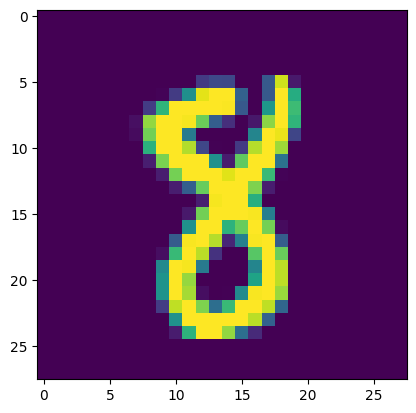

In [16]:
plt.imshow(img)

In [17]:
# 定义生成器
class Generator(nn.Module):
    def __init__(self):
        super(Generator,self).__init__()
        self.main=nn.Sequential(
            nn.Linear(100,256),
            nn.ReLU(),
            nn.Linear(256,512),
            nn.ReLU(),
            nn.Linear(512,28*28*1),
            nn.Tanh()
        )

    def forward(self,x):
        img = self.main(x)
        img = img.view(-1,28,28,1)
        return img

In [18]:
# 定义判定器
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator,self).__init__()
        self.main=nn.Sequential(
            nn.Linear(28*28*1,512),
            nn.LeakyReLU(),
            nn.Linear(512,256),
            nn.LeakyReLU(),
            nn.Linear(256,1),
            nn.Sigmoid()
        )

    def forward(self,x):
        x=x.view(-1,28*28*1)
        x=self.main(x)
        return x

In [21]:
gen = Generator().to(device)
dis = Discriminator().to(device)

In [31]:
# 二元交叉熵损失函数
loss_fn = torch.nn.BCELoss()
# 判别器，生成器的优化器
d_optimizer = torch.optim.Adam(dis.parameters(),lr=0.0001)
g_optimizer = torch.optim.Adam(gen.parameters(),lr=0.0001)

In [32]:
#创建测试的输入
test_input = torch.randn(16, 100, device=device)


In [36]:
def generate_and_save_images(model, epoch, test_input):
    predictions = np.squeeze(model(test_input).cpu().numpy())
    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        #-1到1 变成灰度度，0-1，
        plt.imshow((predictions[i]+1)/2, cmap='gray')
        plt.axis('off')
    # plt.savefig('image_epoch_{}.png'.format(epoch))
    plt.show()


Epoch: 0  D_epoch_loss:  0.004145827965407322  G_epoch_loss: 0.05133917731444041


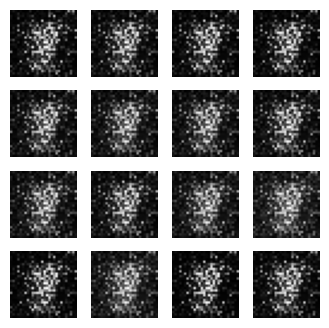

Epoch: 1  D_epoch_loss:  0.003084938265165935  G_epoch_loss: 0.06208255640268326


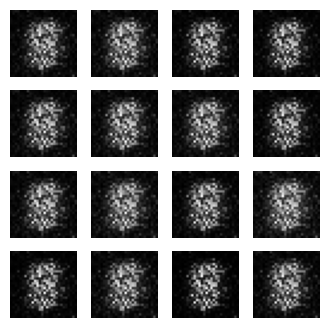

Epoch: 2  D_epoch_loss:  0.0026137481237451235  G_epoch_loss: 0.05961601164340973


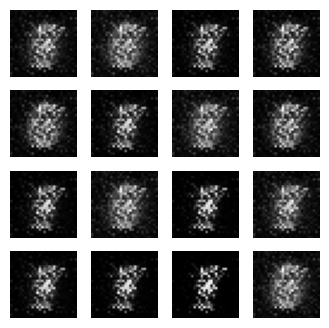

KeyboardInterrupt: 

In [37]:
D_loss = []
G_loss = []

#开始训练
for epoch in range(20):
    D_epoch_loss = 0
    G_epoch_loss = 0
    count = len(train_dl.dataset)
    for step, (img, _) in enumerate(train_dl):
        img = img.to(device)
        size = img.shape[0]
        random_seed = torch.randn(size, 100, device=device)

        #判别器梯度归零
        d_optimizer.zero_grad()
        #将真的图片进行判定
        real_output = dis(img)
        #计算误差
        d_real_loss = loss_fn(real_output, torch.ones_like(real_output, device=device))
        #反向传播
        d_real_loss.backward()


        #生成图片
        generated_img = gen(random_seed)
        #将生成的图片给到判别器进行判断
        fake_output = dis(generated_img.detach())
        #计算判别器判别假的图片的误差
        d_fake_loss = loss_fn(fake_output, torch.zeros_like(fake_output, device=device))
        #反向传播
        d_fake_loss.backward()
        #更新判别器参数
        d_optimizer.step()
        #判别器的总损失
        disc_loss = d_real_loss + d_fake_loss
        
        
        #生成器梯度归零
        g_optimizer.zero_grad()
        #要让生成器生成的图片，给到判别器判断全为真
        fake_output = dis(generated_img)
        #生成器计算误差
        gen_loss = loss_fn(fake_output, torch.ones_like(fake_output, device=device))
        #反向传播
        gen_loss.backward()
        #生成器更新
        g_optimizer.step()
        
        
        with torch.no_grad():
            D_epoch_loss += disc_loss.item()
            G_epoch_loss += gen_loss.item()
        
    with torch.no_grad():
        D_epoch_loss /= count
        G_epoch_loss /= count
        D_loss.append(D_epoch_loss)
        G_loss.append(G_epoch_loss)
        print("Epoch:", epoch, " D_epoch_loss: ", D_epoch_loss, " G_epoch_loss:", G_epoch_loss)
        generate_and_save_images(gen, epoch, test_input)

In [ ]:
# 1. 架构问题（最关键） ：用全连接 MLP 而不是卷积网络，MLP-GAN 在图像生成上几乎不可能生成清晰数字
# 2. 判别器压倒生成器 ： D_loss=0.006 极低，D 太强，G 学不到有效梯度 
# 3. 优化器配置不当 ：Adam 没设置 betas=(0.5, 0.999) ，这是 GAN 训练的标配 
# 4. 数值不稳定 ： BCELoss + Sigmoid 容易梯度消失，应该用 BCEWithLogitsLoss 
# 5. 缺少 BatchNorm ：GAN 训练的关键稳定技巧 6. 缺少权重初始化